In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

import os

print("Current Project Location:")
print(os.getcwd())

print("\nFiles Available:")
print(os.listdir())


Current Project Location:
C:\Users\Rashi Juneja\OneDrive\Desktop\Fintech_DA Proj

Files Available:
['.ipynb_checkpoints', 'fintect_proj.ipynb']


In [3]:

import os

# Create dataset folders
os.makedirs("dataset/raw", exist_ok=True)

print("Dataset folders created successfully!")


Dataset folders created successfully!


In [4]:

import pandas as pd
import numpy as np

np.random.seed(42)

n = 5000

data = {
    "Transaction_ID": [f"TXN{i:05d}" for i in range(1, n+1)],
    "Customer_ID": np.random.choice(
        [f"CUST{i:03d}" for i in range(1, 201)], n
    ),
    "Merchant_ID": np.random.choice(
        [f"MER{i:03d}" for i in range(1, 21)], n
    ),
    "Transaction_Amount": np.random.randint(100, 50000, n),
    "Location": np.random.choice(
        ["Mumbai", "Pune", "Delhi", "Nagpur", "Hyderabad"], n
    ),
    "Payment_Type": np.random.choice(
        ["UPI", "Credit Card", "Debit Card", "Net Banking"], n
    ),
    "Transaction_Date": pd.date_range(
        start="2025-01-01", periods=n, freq="h"
    ),
    "Fraud_Status": np.random.choice(
        [0, 1], n, p=[0.95, 0.05]
    )
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print(df.head())


Dataset created successfully!
  Transaction_ID Customer_ID Merchant_ID  Transaction_Amount   Location  \
0       TXN00001     CUST103      MER019               17370  Hyderabad   
1       TXN00002     CUST180      MER003               21802     Mumbai   
2       TXN00003     CUST093      MER004                4482       Pune   
3       TXN00004     CUST015      MER005                1885     Mumbai   
4       TXN00005     CUST107      MER001               45898  Hyderabad   

  Payment_Type    Transaction_Date  Fraud_Status  
0          UPI 2025-01-01 00:00:00             0  
1          UPI 2025-01-01 01:00:00             0  
2   Debit Card 2025-01-01 02:00:00             0  
3  Net Banking 2025-01-01 03:00:00             0  
4  Credit Card 2025-01-01 04:00:00             0  


In [5]:

df.to_csv("dataset/raw/transactions.csv", index=False)

print("Dataset saved successfully!")


Dataset saved successfully!


In [6]:

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nTotal Transactions:", len(df))


Dataset Shape: (5000, 8)

Columns: ['Transaction_ID', 'Customer_ID', 'Merchant_ID', 'Transaction_Amount', 'Location', 'Payment_Type', 'Transaction_Date', 'Fraud_Status']

Total Transactions: 5000


In [7]:

# Load transaction dataset

df = pd.read_csv("dataset/raw/transactions.csv")

# Display first 5 rows
df.head()


,Transaction_ID,Customer_ID,Merchant_ID,Transaction_Amount,Location,Payment_Type,Transaction_Date,Fraud_Status
0,TXN00001,CUST103,MER019,17370,Hyderabad,UPI,2025-01-01 00:00:00,0
1,TXN00002,CUST180,MER003,21802,Mumbai,UPI,2025-01-01 01:00:00,0
2,TXN00003,CUST093,MER004,4482,Pune,Debit Card,2025-01-01 02:00:00,0
3,TXN00004,CUST015,MER005,1885,Mumbai,Net Banking,2025-01-01 03:00:00,0
4,TXN00005,CUST107,MER001,45898,Hyderabad,Credit Card,2025-01-01 04:00:00,0


In [8]:

# Check dataset information
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   Transaction_ID      5000 non-null   str  
 1   Customer_ID         5000 non-null   str  
 2   Merchant_ID         5000 non-null   str  
 3   Transaction_Amount  5000 non-null   int64
 4   Location            5000 non-null   str  
 5   Payment_Type        5000 non-null   str  
 6   Transaction_Date    5000 non-null   str  
 7   Fraud_Status        5000 non-null   int64
dtypes: int64(2), str(6)
memory usage: 312.6 KB


In [9]:

df.describe()


,Transaction_Amount,Fraud_Status
count,5000.000000,5000.000000
mean,24669.194000,0.056000
std,14426.489652,0.229945
min,105.000000,0.000000
25%,12099.250000,0.000000
50%,24368.000000,0.000000
75%,37096.750000,0.000000
max,49995.000000,1.000000


In [10]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Transaction_ID        0
Customer_ID           0
Merchant_ID           0
Transaction_Amount    0
Location              0
Payment_Type          0
Transaction_Date      0
Fraud_Status          0
dtype: int64

Duplicate Records:
0


In [11]:
# Remove duplicate records
df = df.drop_duplicates()

print("Duplicates removed successfully!")
print("New Dataset Shape:", df.shape)

Duplicates removed successfully!
New Dataset Shape: (5000, 8)


In [12]:
# Convert Transaction_Date into datetime format
df['Transaction_Date'] = pd.to_datetime(df['Transaction_Date'])

print("Date converted successfully!")
print(df['Transaction_Date'].dtype)

# Display first 5 dates
print(df['Transaction_Date'].head())

Date converted successfully!
datetime64[us]
0   2025-01-01 00:00:00
1   2025-01-01 01:00:00
2   2025-01-01 02:00:00
3   2025-01-01 03:00:00
4   2025-01-01 04:00:00
Name: Transaction_Date, dtype: datetime64[us]


In [13]:
# Count Fraud and Non-Fraud Transactions

print("Fraud Status Count:")
print(df['Fraud_Status'].value_counts())

# Calculate Fraud Percentage
print("\nFraud Percentage:")
print(df['Fraud_Status'].value_counts(normalize=True) * 100)

Fraud Status Count:
Fraud_Status
0    4720
1     280
Name: count, dtype: int64

Fraud Percentage:
Fraud_Status
0    94.4
1     5.6
Name: proportion, dtype: float64


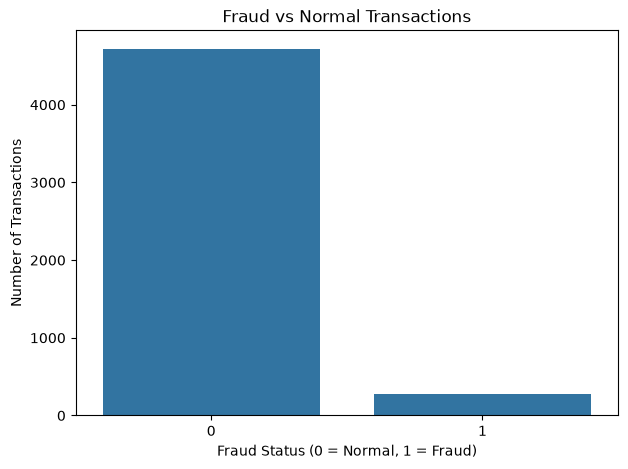

In [14]:
plt.figure(figsize=(7,5))

sns.countplot(x='Fraud_Status', data=df)

plt.title('Fraud vs Normal Transactions')
plt.xlabel('Fraud Status (0 = Normal, 1 = Fraud)')
plt.ylabel('Number of Transactions')

plt.show()

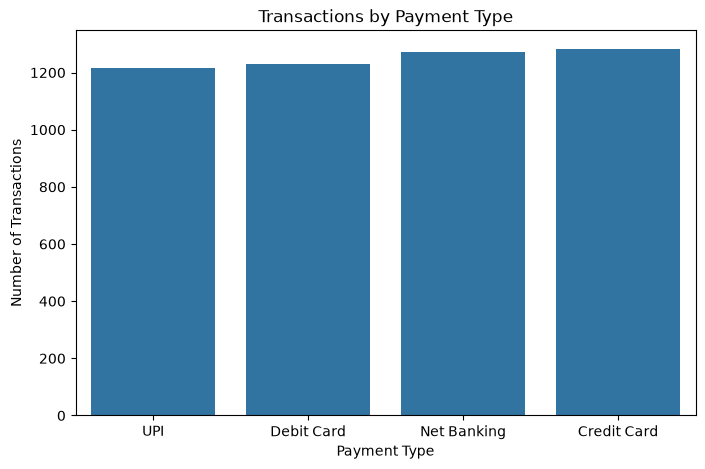

In [15]:
plt.figure(figsize=(8,5))

sns.countplot(x='Payment_Type', data=df)

plt.title('Transactions by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Number of Transactions')

plt.show()

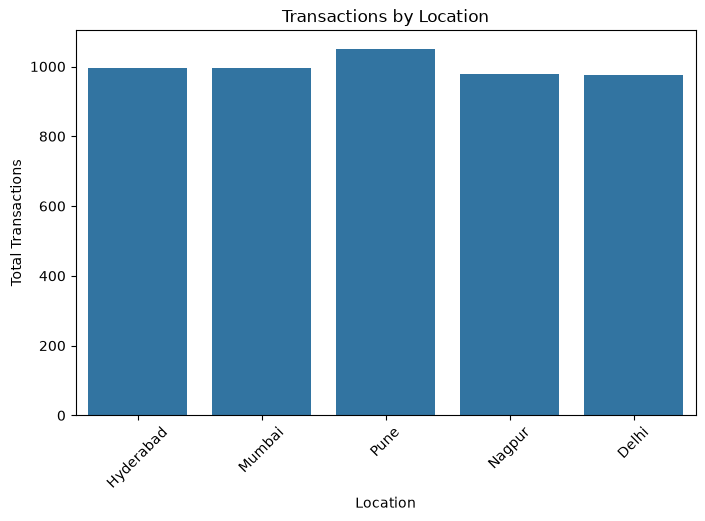

In [16]:
plt.figure(figsize=(8,5))

sns.countplot(x='Location', data=df)

plt.title('Transactions by Location')
plt.xlabel('Location')
plt.ylabel('Total Transactions')
plt.xticks(rotation=45)

plt.show()

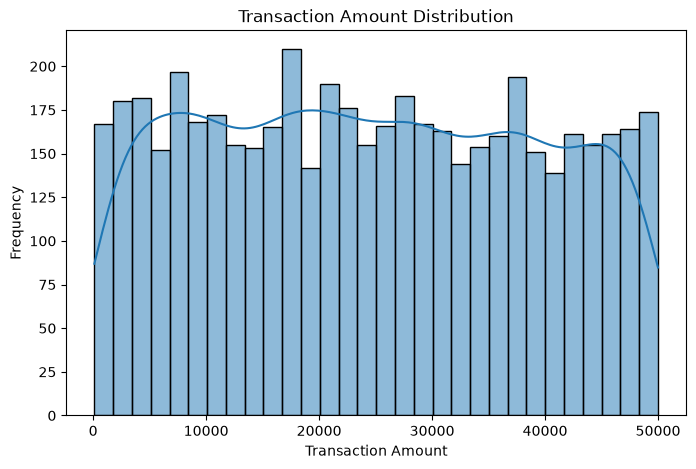

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(df['Transaction_Amount'], bins=30, kde=True)

plt.title('Transaction Amount Distribution')
plt.xlabel('Transaction Amount')
plt.ylabel('Frequency')

plt.show()

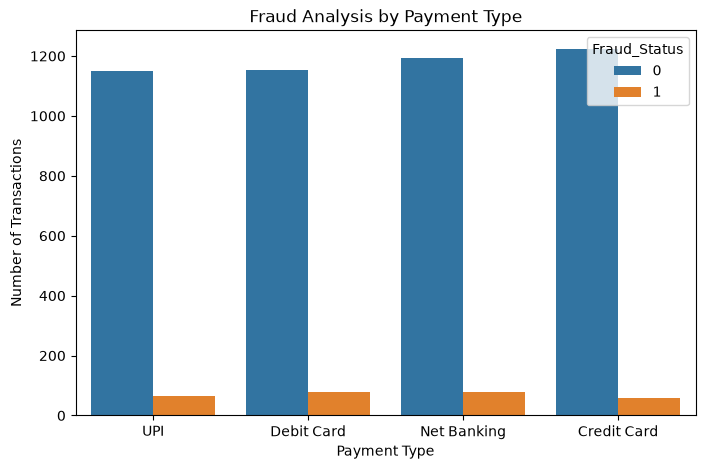

In [18]:
plt.figure(figsize=(8,5))

sns.countplot(x='Payment_Type', hue='Fraud_Status', data=df)

plt.title('Fraud Analysis by Payment Type')
plt.xlabel('Payment Type')
plt.ylabel('Number of Transactions')

plt.show()

In [19]:
df.to_csv('dataset/cleaned_transactions.csv', index=False)

print("Clean Dataset Saved Successfully!")

Clean Dataset Saved Successfully!


In [20]:
import os

print(os.path.abspath("dataset/cleaned_transactions.csv"))

C:\Users\Rashi Juneja\OneDrive\Desktop\Fintech_DA Proj\dataset\cleaned_transactions.csv
